# T1 Late-Delivery Classifier (Member C)

Order-level binary classifier for `Late_delivery_risk`, built on member A's cleaned data.

**Agreed definitions**
- Unit: one row per `Order Id` (item rows aggregated; an order never spans two splits).
- `Shipping canceled` orders (2,855) are excluded from training/evaluation (their label is forced to 0) and analysed separately in C5.
- Leakage-prone post-fulfilment fields are never used: `Days for shipping (real)`, `shipping date`, `Delivery Status`, `Order Status`, profit fields (`Benefit per order`, `Order Profit Per Order`, `Order Item Profit Ratio`). `Order Id` is an identifier only.
- `Days for shipment (scheduled)` is a 1:1 recoding of `Shipping Mode`, so only `shipping_mode` is used.
- Chronological split: Train 2015-01 – 2017-03, Validation 2017-04 – 2017-09, Test 2017-10 – 2018-01.
- Preprocessing (imputation, scaling, one-hot) is fitted on training data only, inside the sklearn `Pipeline`.
- Hyper-parameters and the alert threshold are chosen on Validation; Test is used once for the final report.
- The shipped model is the Train-fitted model whose threshold was chosen on Validation (no refit, so the threshold stays valid).
- Data caveat: markets appear in blocks of months (Validation = LATAM, Europe; Test = Europe, Pacific Asia) and from 2017-10
  almost every order holds a single product, so segment results only cover the markets present in each period.

**Models (simple → complex)**: mode-only benchmark → Logistic Regression (linear) → CART Decision Tree (simple non-linear)
→ Random Forest (bagging ensemble) → XGBoost (gradient-boosting ensemble, added following the tutor's feedback).

In [1]:
import json, platform, sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_auc_score, roc_curve

C_DIR = Path.cwd()
sys.path.insert(0, str(C_DIR))
import t1_pipeline as t1

MODEL_DIR, RES_DIR = C_DIR / "models", C_DIR / "results"
FIG_DIR = RES_DIR / "figures"
for d in (MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 30)
print("python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| pandas", pd.__version__)

python 3.14.6 | scikit-learn 1.9.0 | xgboost 3.4.1 | pandas 3.0.3


## 1. Data (C1)
Order-level features are rebuilt from `A/cleaned_order_items.csv` and reconciled with `A/order_level_model_data.csv`.

In [2]:
orders, canceled = t1.load_orders()

a = pd.read_csv(t1.ORDERS_PATH).set_index("Order Id").sort_index()
o = orders.set_index("Order Id").sort_index()
check_cols = ["total_quantity", "total_sales", "total_discount", "item_count", "unique_products",
              "unique_categories", "scheduled_days", t1.TARGET]
assert a.index.equals(o.index) and all(np.allclose(a[c], o[c]) for c in check_cols)
assert (orders.groupby("shipping_mode")["scheduled_days"].nunique() == 1).all()

y_all = orders[t1.TARGET]
print(f"Modelling orders: {len(orders):,}  (late {y_all.sum():,} / not late {(1 - y_all).sum():,}, late rate {y_all.mean():.1%})")
print(f"Canceled orders excluded: {len(canceled):,}")
print("Reconciled with A/order_level_model_data.csv: OK")
orders.groupby("shipping_mode").agg(orders=(t1.TARGET, "size"), late_rate=(t1.TARGET, "mean"),
                                    scheduled_days=("scheduled_days", "first"))

Modelling orders: 62,897  (late 36,048 / not late 26,849, late rate 57.3%)
Canceled orders excluded: 2,855
Reconciled with A/order_level_model_data.csv: OK


,orders,late_rate,scheduled_days
shipping_mode,,,
First Class,9602,1.0000,1
Same Day,3407,0.4837,0
Second Class,12256,0.7999,2
Standard Class,37632,0.3985,4


In [3]:
feature_doc = pd.DataFrame(
    [(c, "categorical", "order attribute") for c in t1.CAT_FULL]
    + [(c, "numeric", "sum / count over order items") for c in t1.BASE_NUM]
    + [("net_sales", "numeric", "total_sales - total_discount"),
       ("discount_rate", "numeric", "total_discount / total_sales"),
       ("order_hour / order_dow / order_month", "numeric", "from order_date")]
    + [("dept_qty_*  (11 columns)", "numeric", "units bought per department")],
    columns=["feature", "type", "definition"])
feature_doc.to_csv(RES_DIR / "feature_list.csv", index=False)
print("Pipeline input columns:", t1.INPUT_COLS)
feature_doc

Pipeline input columns: ['order_date', 'shipping_mode', 'market', 'order_region', 'payment_type', 'customer_segment', 'total_quantity', 'total_sales', 'total_discount', 'item_count', 'unique_products', 'unique_categories', 'dept_qty_apparel', 'dept_qty_book_shop', 'dept_qty_discs_shop', 'dept_qty_fan_shop', 'dept_qty_fitness', 'dept_qty_footwear', 'dept_qty_golf', 'dept_qty_health_and_beauty', 'dept_qty_outdoors', 'dept_qty_pet_shop', 'dept_qty_technology']


,feature,type,definition
0,shipping_mode,categorical,order attribute
1,market,categorical,order attribute
2,order_region,categorical,order attribute
3,payment_type,categorical,order attribute
4,customer_segment,categorical,order attribute
5,total_quantity,numeric,sum / count over order items
6,total_sales,numeric,sum / count over order items
7,total_discount,numeric,sum / count over order items
8,item_count,numeric,sum / count over order items
9,unique_products,numeric,sum / count over order items


## 2. Chronological split

In [4]:
train, valid, test = t1.chronological_split(orders)
Xtr, ytr = train[t1.INPUT_COLS], train[t1.TARGET]
Xva, yva = valid[t1.INPUT_COLS], valid[t1.TARGET]
Xte, yte = test[t1.INPUT_COLS], test[t1.TARGET]

split_summary = pd.DataFrame({
    name: {"start": d["order_date"].min().date(), "end": d["order_date"].max().date(),
           "orders": len(d), "late_rate": round(d[t1.TARGET].mean(), 4)}
    for name, d in [("Train", train), ("Validation", valid), ("Test", test)]}).T
split_summary.to_csv(RES_DIR / "split_summary.csv")
split_summary

,start,end,orders,late_rate
Train,2015-01-01,2017-03-31,44883,0.5733
Validation,2017-04-01,2017-09-30,9971,0.5698
Test,2017-10-01,2018-01-31,8043,0.5764


## 3. Naive benchmark
Score = training late rate of the order's shipping mode. Every model must beat this.

In [5]:
mode_base = t1.ModeRateBaseline().fit(Xtr, ytr)
print(f"Mode-only benchmark, validation ROC-AUC: {roc_auc_score(yva, mode_base.predict_proba(Xva)[:, 1]):.4f}")

Mode-only benchmark, validation ROC-AUC: 0.7419


## 4. Logistic Regression baseline (C2)
Tuned on validation for both feature sets; the Full version is exported for member E's end-to-end test.

In [6]:
GRIDS = {
    "LogisticRegression": {"C": [0.001, 0.01, 0.1, 1, 10]},
    "DecisionTree": {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [20, 100, 500]},
    "RandomForest": {"n_estimators": [300], "max_depth": [8, 16, None],
                     "min_samples_leaf": [10, 50, 200], "max_features": ["sqrt", 0.5]},
    "XGBoost": {"n_estimators": [200, 500], "max_depth": [3, 5, 7], "learning_rate": [0.03, 0.1],
                "min_child_weight": [1, 20], "subsample": [0.8], "colsample_bytree": [0.8]},
}
tuning = {}
for fs in t1.FEATURE_SETS:
    tuning[("LogisticRegression", fs)] = t1.tune(t1.MODEL_FACTORIES["LogisticRegression"],
                                                 GRIDS["LogisticRegression"], fs, train, valid)
pd.concat({k[1]: v for k, v in tuning.items()}, names=["feature_set_", "rank"])

C        params feature_set  valid_auc
feature_set_ rank                                             
Full         0    10.0000     {'C': 10}        Full     0.7487
             1     1.0000      {'C': 1}        Full     0.7484
             2     0.1000    {'C': 0.1}        Full     0.7480
             3     0.0100   {'C': 0.01}        Full     0.7455
             4     0.0010  {'C': 0.001}        Full     0.7452
NoMode       0     0.0010  {'C': 0.001}      NoMode     0.5264
             1     0.0100   {'C': 0.01}      NoMode     0.5256
             2     0.1000    {'C': 0.1}      NoMode     0.5253
             3     1.0000      {'C': 1}      NoMode     0.5252
             4    10.0000     {'C': 10}      NoMode     0.5252

In [7]:
def best_params(algo, fs):
    return dict(tuning[(algo, fs)].iloc[0]["params"])


def to_json(obj):
    return obj.item() if hasattr(obj, "item") else str(obj)


def save_model(pipe, name, algo, fs, params, threshold, fit_end, metrics):
    meta = {
        "model_name": name,
        "model_version": f"T1-{algo}-{fs}-{pd.Timestamp.now():%Y%m%d}",
        "algorithm": algo, "feature_set": fs, "params": params,
        "threshold": threshold,
        "threshold_rule": "highest validation precision with validation recall >= 0.75",
        "fit_start": str(orders["order_date"].min().date()), "fit_end": str(fit_end.date()),
        "input_columns": t1.INPUT_COLS,
        "required_columns": [c for c in t1.INPUT_COLS if c not in t1.DEPT_COLS],
        "optional_zero_columns": t1.DEPT_COLS,
        "output": {"risk_score": "P(late)", "pred_label": "1 if risk_score >= threshold"},
        "metrics": metrics,
        "python_version": platform.python_version(), "sklearn_version": sklearn.__version__,
        "xgboost_version": xgboost.__version__,
        "created_at": str(pd.Timestamp.now().round("s")),
    }
    joblib.dump(pipe, MODEL_DIR / f"{name}.joblib")
    (MODEL_DIR / f"{name}_meta.json").write_text(json.dumps(meta, indent=2, default=to_json))
    return meta


lr_params = best_params("LogisticRegression", "Full")
lr_base = t1.make_pipeline(t1.MODEL_FACTORIES["LogisticRegression"](**lr_params), "Full").fit(Xtr, ytr)
p_va = lr_base.predict_proba(Xva)[:, 1]
lr_thr = t1.choose_threshold(yva, p_va)
lr_valid_metrics = t1.evaluate(yva, p_va, lr_thr)
baseline_meta = save_model(lr_base, "t1_baseline", "LogisticRegression", "Full", lr_params, lr_thr,
                           t1.TRAIN_END, {"validation": lr_valid_metrics})

example = test.head(3)[["Order Id"] + t1.INPUT_COLS].rename(columns={"Order Id": "order_id"})
example["order_date"] = example["order_date"].dt.strftime("%Y-%m-%d %H:%M:%S")
(MODEL_DIR / "example_request.json").write_text(
    json.dumps({"instances": json.loads(example.to_json(orient="records"))}, indent=2))
print("Baseline params:", lr_params, "| threshold:", round(lr_thr, 4))
pd.Series(lr_valid_metrics)

Baseline params: {'C': 10} | threshold: 0.4082


roc_auc         0.7487
recall          0.7500
precision       0.6726
f1              0.7092
alert_rate      0.6353
fpr             0.4834
threshold       0.4082
tn           2216.0000
fp           2074.0000
fn           1420.0000
tp           4261.0000
n            9971.0000
dtype: float64

## 5. CART Decision Tree, Random Forest and XGBoost (C3)
Non-linear models from simple to complex: a single CART tree, a bagging ensemble (Random Forest) and a gradient-boosting
ensemble (XGBoost). All are tuned on validation ROC-AUC with both feature sets.

In [8]:
for algo in ["DecisionTree", "RandomForest", "XGBoost"]:
    for fs in t1.FEATURE_SETS:
        tuning[(algo, fs)] = t1.tune(t1.MODEL_FACTORIES[algo], GRIDS[algo], fs, train, valid)

# second pass: number of trees around the best RF configuration
for fs in t1.FEATURE_SETS:
    best = best_params("RandomForest", fs)
    grid = {k: [v] for k, v in best.items() if k != "n_estimators"} | {"n_estimators": [100, 300, 600]}
    extra = t1.tune(t1.MODEL_FACTORIES["RandomForest"], grid, fs, train, valid)
    tuning[("RandomForest", fs)] = (pd.concat([tuning[("RandomForest", fs)], extra])
                                    .loc[lambda d: ~d["params"].astype(str).duplicated()]
                                    .sort_values("valid_auc", ascending=False).reset_index(drop=True))

tuning_log = pd.concat([v.assign(algorithm=k[0]) for k, v in tuning.items()], ignore_index=True)
tuning_log = tuning_log[["algorithm", "feature_set", "valid_auc", "params"]]
tuning_log.to_csv(RES_DIR / "tuning_log.csv", index=False)
tuning_log.groupby(["algorithm", "feature_set"]).head(3)

,algorithm,feature_set,valid_auc,params
0,LogisticRegression,Full,0.7487,{'C': 10}
1,LogisticRegression,Full,0.7484,{'C': 1}
2,LogisticRegression,Full,0.7480,{'C': 0.1}
5,LogisticRegression,NoMode,0.5264,{'C': 0.001}
6,LogisticRegression,NoMode,0.5256,{'C': 0.01}
7,LogisticRegression,NoMode,0.5253,{'C': 0.1}
10,DecisionTree,Full,0.7767,"{'max_depth': 5, 'min_samples_leaf': 500}"
11,DecisionTree,Full,0.7764,"{'max_depth': 8, 'min_samples_leaf': 500}"
12,DecisionTree,Full,0.7748,"{'max_depth': 5, 'min_samples_leaf': 100}"
25,DecisionTree,NoMode,0.5233,"{'max_depth': 3, 'min_samples_leaf': 100}"


In [9]:
COMPLEXITY = {"ModeOnlyBenchmark": "0 benchmark", "LogisticRegression": "1 simple linear",
              "DecisionTree": "2 simple non-linear", "RandomForest": "3 complex ensemble (bagging)",
              "XGBoost": "4 complex ensemble (boosting)"}
fitted, rows = {}, []  # every candidate is fitted on Train only; thresholds chosen on Validation
cands = [("ModeOnlyBenchmark", "Full", None)] + [(a, fs, best_params(a, fs))
         for a in ["LogisticRegression", "DecisionTree", "RandomForest", "XGBoost"] for fs in t1.FEATURE_SETS]
for algo, fs, params in cands:
    pipe = (t1.ModeRateBaseline() if params is None
            else t1.make_pipeline(t1.MODEL_FACTORIES[algo](**params), fs)).fit(Xtr, ytr)
    s = pipe.predict_proba(Xva)[:, 1]
    thr = t1.choose_threshold(yva, s)
    fitted[(algo, fs)] = {"params": params, "threshold": thr, "pipe": pipe}
    rows.append({"model": algo, "complexity": COMPLEXITY[algo], "feature_set": fs, "params": params,
                 **t1.evaluate(yva, s, thr)})
comparison = pd.DataFrame(rows)
comparison.to_csv(RES_DIR / "model_comparison_validation.csv", index=False)
comparison[["model", "complexity", "feature_set", "roc_auc", "recall", "precision", "f1", "alert_rate", "threshold", "params"]]

,model,complexity,feature_set,roc_auc,recall,precision,f1,alert_rate,threshold,params
0,ModeOnlyBenchmark,0 benchmark,Full,0.7419,1.0000,0.5698,0.7259,1.0000,0.3997,None
1,LogisticRegression,1 simple linear,Full,0.7487,0.7500,0.6726,0.7092,0.6353,0.4082,{'C': 10}
2,LogisticRegression,1 simple linear,NoMode,0.5264,0.7504,0.5803,0.6545,0.7367,0.5535,{'C': 0.001}
3,DecisionTree,2 simple non-linear,Full,0.7767,0.9113,0.6180,0.7365,0.8401,0.4023,"{'max_depth': 5, 'min_samples_leaf': 500}"
4,DecisionTree,2 simple non-linear,NoMode,0.5233,1.0000,0.5698,0.7259,1.0000,0.4348,"{'max_depth': 3, 'min_samples_leaf': 100}"
5,RandomForest,3 complex ensemble (bagging),Full,0.7755,0.7500,0.7063,0.7275,0.6051,0.4030,"{'max_depth': 16, 'max_features': 0.5, 'min_sa..."
6,RandomForest,3 complex ensemble (bagging),NoMode,0.5266,0.7525,0.5839,0.6576,0.7342,0.5558,"{'max_depth': 8, 'max_features': 'sqrt', 'min_..."
7,XGBoost,4 complex ensemble (boosting),Full,0.7766,0.7507,0.7072,0.7283,0.6049,0.4059,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."
8,XGBoost,4 complex ensemble (boosting),NoMode,0.5243,0.7555,0.5809,0.6568,0.7410,0.5450,"{'colsample_bytree': 0.8, 'learning_rate': 0.0..."


## 6. Final model, threshold and test evaluation (C4)
Selection rule: highest validation ROC-AUC among Full-feature models; candidates within 0.005 AUC of the best are
ranked by validation precision at the recall >= 0.75 operating point. The selected model is the Train-fitted pipeline
with its validation threshold; Test is scored once. The best NoMode model and the mode-only benchmark are scored the
same way for the include/exclude comparison.

In [10]:
full_models = comparison[(comparison.feature_set == "Full") & (comparison.model != "ModeOnlyBenchmark")]
shortlist = full_models[full_models.roc_auc >= full_models.roc_auc.max() - 0.005]
FINAL_ALGO = shortlist.sort_values(["precision", "roc_auc"], ascending=False).iloc[0]["model"]
NOMODE_ALGO = comparison[comparison.feature_set == "NoMode"].sort_values("roc_auc", ascending=False).iloc[0]["model"]
print("Shortlist (within 0.005 AUC):", shortlist[["model", "roc_auc", "recall", "precision"]].to_dict("records"))
print("Final model:", FINAL_ALGO, fitted[(FINAL_ALGO, "Full")]["params"])
print("Best NoMode model:", NOMODE_ALGO, fitted[(NOMODE_ALGO, "NoMode")]["params"])

final_pipe = fitted[(FINAL_ALGO, "Full")]["pipe"]
FINAL_THR = fitted[(FINAL_ALGO, "Full")]["threshold"]
score_test = lambda key: (fitted[key]["pipe"].predict_proba(Xte)[:, 1], fitted[key]["threshold"])
test_scores = {
    f"{FINAL_ALGO} (Full, final)": score_test((FINAL_ALGO, "Full")),
    f"{NOMODE_ALGO} (NoMode)": score_test((NOMODE_ALGO, "NoMode")),
    "Mode-only benchmark": score_test(("ModeOnlyBenchmark", "Full")),
}
test_eval = pd.DataFrame({k: t1.evaluate(yte, s, thr) for k, (s, thr) in test_scores.items()}).T
test_eval.to_csv(RES_DIR / "test_evaluation.csv")
final_test = test_eval.iloc[0]
print(f"Targets on test -> ROC-AUC >= 0.80: {final_test.roc_auc:.4f} ({'met' if final_test.roc_auc >= 0.80 else 'NOT met'}); "
      f"late recall >= 0.75: {final_test.recall:.4f} ({'met' if final_test.recall >= 0.75 else 'NOT met'})")
test_eval

Shortlist (within 0.005 AUC): [{'model': 'DecisionTree', 'roc_auc': 0.7766819755378107, 'recall': 0.911283224784369, 'precision': 0.6180016712426883}, {'model': 'RandomForest', 'roc_auc': 0.7754845107951955, 'recall': 0.7500440063369125, 'precision': 0.7062821150339798}, {'model': 'XGBoost', 'roc_auc': 0.7765863925430903, 'recall': 0.7507481077275128, 'precision': 0.7071795722102471}]
Final model: XGBoost {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 20, 'n_estimators': 200, 'subsample': 0.8}
Best NoMode model: RandomForest {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 200, 'n_estimators': 100}
Targets on test -> ROC-AUC >= 0.80: 0.7766 (NOT met); late recall >= 0.75: 0.7744 (met)


,roc_auc,recall,precision,f1,alert_rate,fpr,threshold,tn,fp,fn,tp,n
"XGBoost (Full, final)",0.7766,0.7744,0.6960,0.7331,0.6413,0.4602,0.4059,1839.0000,1568.0000,1046.0000,3590.0000,8043.0000
RandomForest (NoMode),0.5317,0.7390,0.5851,0.6531,0.7280,0.7129,0.5558,978.0000,2429.0000,1210.0000,3426.0000,8043.0000
Mode-only benchmark,0.7447,1.0000,0.5764,0.7313,1.0000,1.0000,0.3997,0.0000,3407.0000,0.0000,4636.0000,8043.0000


In [11]:
s_final = test_scores[f"{FINAL_ALGO} (Full, final)"][0]
order = np.argsort(-s_final, kind="stable")
capacity = []
for k in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flagged = np.zeros(len(s_final), bool); flagged[order[: int(round(k * len(s_final)))]] = True
    tp = (flagged & (yte.to_numpy() == 1)).sum()
    capacity.append({"alert_share": k, "orders_flagged": flagged.sum(), "recall": tp / yte.sum(), "precision": tp / flagged.sum()})
capacity = pd.DataFrame(capacity)
capacity.to_csv(RES_DIR / "test_capacity_table.csv", index=False)
capacity

,alert_share,orders_flagged,recall,precision
0,0.1000,804,0.1734,1.0000
1,0.2000,1609,0.3415,0.9838
2,0.3000,2413,0.4795,0.9213
3,0.4000,3217,0.6038,0.8701
4,0.5000,4022,0.6752,0.7782
5,0.6000,4826,0.7463,0.7169
6,0.7000,5630,0.8115,0.6682
7,0.8000,6434,0.8788,0.6332


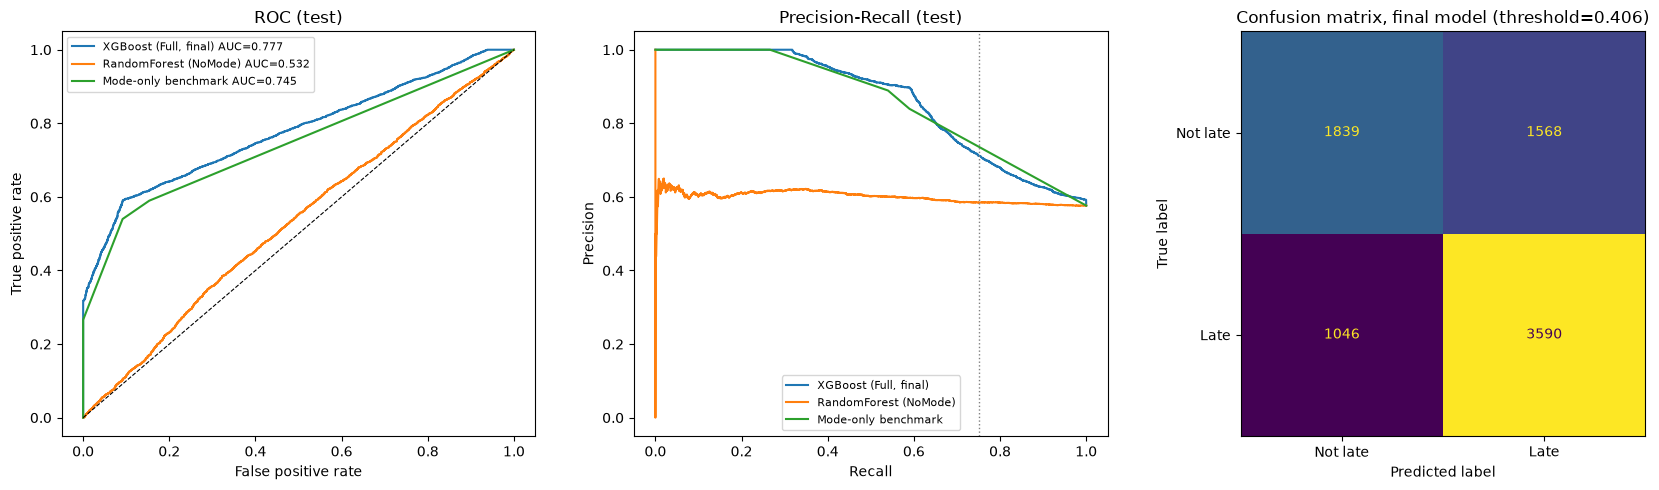

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for name, (s, _) in test_scores.items():
    fpr, tpr, _ = roc_curve(yte, s); axes[0].plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(yte, s):.3f}")
    pr, rc, _ = precision_recall_curve(yte, s); axes[1].plot(rc, pr, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set(title="ROC (test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axvline(0.75, color="grey", ls=":", lw=1); axes[1].set(title="Precision-Recall (test)", xlabel="Recall", ylabel="Precision")
for ax in axes[:2]: ax.legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(yte, (s_final >= FINAL_THR).astype(int), display_labels=["Not late", "Late"],
                                        ax=axes[2], colorbar=False)
axes[2].set_title(f"Confusion matrix, final model (threshold={FINAL_THR:.3f})")
plt.tight_layout(); fig.savefig(FIG_DIR / "test_roc_pr_confusion.png", dpi=150); plt.show()

### Target achievability check
Within Second Class and Standard Class orders the label looks random with respect to all pre-shipment features. The only
structure beyond shipping mode is a **noon cut-off for Same Day orders**. A lookup of training late rates by
(shipping mode, Same Day placed after 12:00), learned on Train, shows the practical ceiling for these features.

In [13]:
def lookup_key(df):
    same_day = df["shipping_mode"] == "Same Day"
    suffix = np.where(same_day & (df["order_date"].dt.hour >= 12), " (>=12:00)", np.where(same_day, " (<12:00)", ""))
    return df["shipping_mode"] + pd.Series(suffix, index=df.index)

rates = train.groupby(lookup_key(train))[t1.TARGET].agg(["size", "mean"]).rename(columns={"size": "orders", "mean": "late_rate"})
display(rates)
ceiling_auc = roc_auc_score(yte, lookup_key(test).map(rates["late_rate"]))
within = pd.DataFrame({m: {"orders": len(g), "late_rate": g[t1.TARGET].mean(),
                           "final_model_auc_within_mode": roc_auc_score(g[t1.TARGET], s_final[test.index.get_indexer(g.index)])
                           if g[t1.TARGET].nunique() > 1 else np.nan}
                       for m, g in test.groupby("shipping_mode")}).T
print(f"Lookup ceiling, test ROC-AUC: {ceiling_auc:.4f}  vs final model {final_test.roc_auc:.4f}")
within

,orders,late_rate
First Class,6872,1.0000
Same Day (<12:00),1289,0.0000
Same Day (>=12:00),1139,1.0000
Second Class,8731,0.8003
Standard Class,26852,0.3997


Lookup ceiling, test ROC-AUC: 0.7762  vs final model 0.7766


,orders,late_rate,final_model_auc_within_mode
First Class,1233.0000,1.0000,NaN
Same Day,442.0000,0.5226,1.0000
Second Class,1582.0000,0.8028,0.5026
Standard Class,4786.0000,0.3974,0.5009


### Simple vs complex models
Validation and test ROC-AUC of every tuned candidate, ordered from simple to complex. The test column is reported only
after the final model and threshold were frozen on validation; it is not used for selection. If the complex ensembles
do not beat the simple tree or the five-cell lookup ceiling, extra model complexity brings no benefit for this problem.

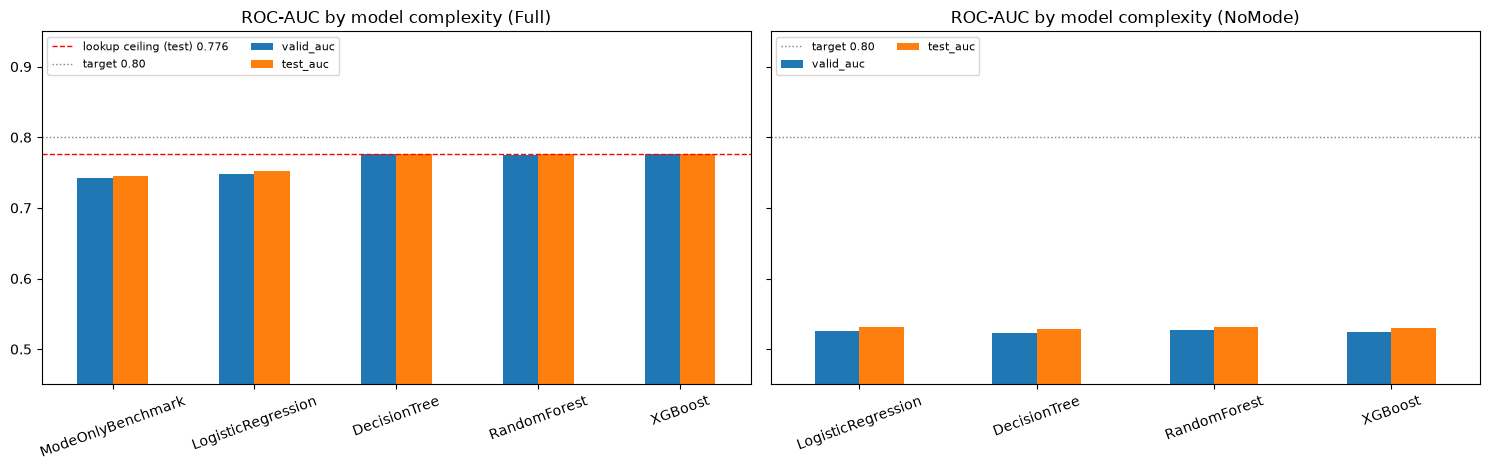

,model,complexity,feature_set,valid_auc,test_auc,test_recall,test_precision,test_f1
0,ModeOnlyBenchmark,0 benchmark,Full,0.7419,0.7447,1.0000,0.5764,0.7313
1,LogisticRegression,1 simple linear,Full,0.7487,0.7526,0.7724,0.6710,0.7181
2,DecisionTree,2 simple non-linear,Full,0.7767,0.7760,0.9756,0.5995,0.7427
3,RandomForest,3 complex ensemble (bagging),Full,0.7755,0.7767,0.8069,0.6728,0.7338
4,XGBoost,4 complex ensemble (boosting),Full,0.7766,0.7766,0.7744,0.6960,0.7331
5,LogisticRegression,1 simple linear,NoMode,0.5264,0.5307,0.7431,0.5855,0.6549
6,DecisionTree,2 simple non-linear,NoMode,0.5233,0.5280,1.0000,0.5764,0.7313
7,RandomForest,3 complex ensemble (bagging),NoMode,0.5266,0.5317,0.7390,0.5851,0.6531
8,XGBoost,4 complex ensemble (boosting),NoMode,0.5243,0.5302,0.8028,0.5836,0.6759


In [14]:
complexity_rows = []
for (algo, fs), f in fitted.items():
    s = f["pipe"].predict_proba(Xte)[:, 1]
    m = t1.evaluate(yte, s, f["threshold"])
    complexity_rows.append({"model": algo, "complexity": COMPLEXITY[algo], "feature_set": fs,
                            "valid_auc": comparison.loc[(comparison.model == algo) & (comparison.feature_set == fs), "roc_auc"].iloc[0],
                            "test_auc": m["roc_auc"], "test_recall": m["recall"], "test_precision": m["precision"], "test_f1": m["f1"]})
complexity_cmp = pd.DataFrame(complexity_rows).sort_values(["feature_set", "complexity"]).reset_index(drop=True)
complexity_cmp.to_csv(RES_DIR / "simple_vs_complex.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, fs in zip(axes, ["Full", "NoMode"]):
    d = complexity_cmp[complexity_cmp.feature_set == fs].set_index("model")[["valid_auc", "test_auc"]]
    d.plot.bar(ax=ax, rot=20)
    if fs == "Full":
        ax.axhline(ceiling_auc, color="red", ls="--", lw=1, label=f"lookup ceiling (test) {ceiling_auc:.3f}")
    ax.axhline(0.80, color="grey", ls=":", lw=1, label="target 0.80")
    ax.set(title=f"ROC-AUC by model complexity ({fs})", xlabel="", ylim=(0.45, 0.95)); ax.legend(fontsize=8, loc="upper left", ncol=2)
plt.tight_layout(); fig.savefig(FIG_DIR / "simple_vs_complex.png", dpi=150); plt.show()
complexity_cmp

## 7. Feature importance and error analysis (C5)

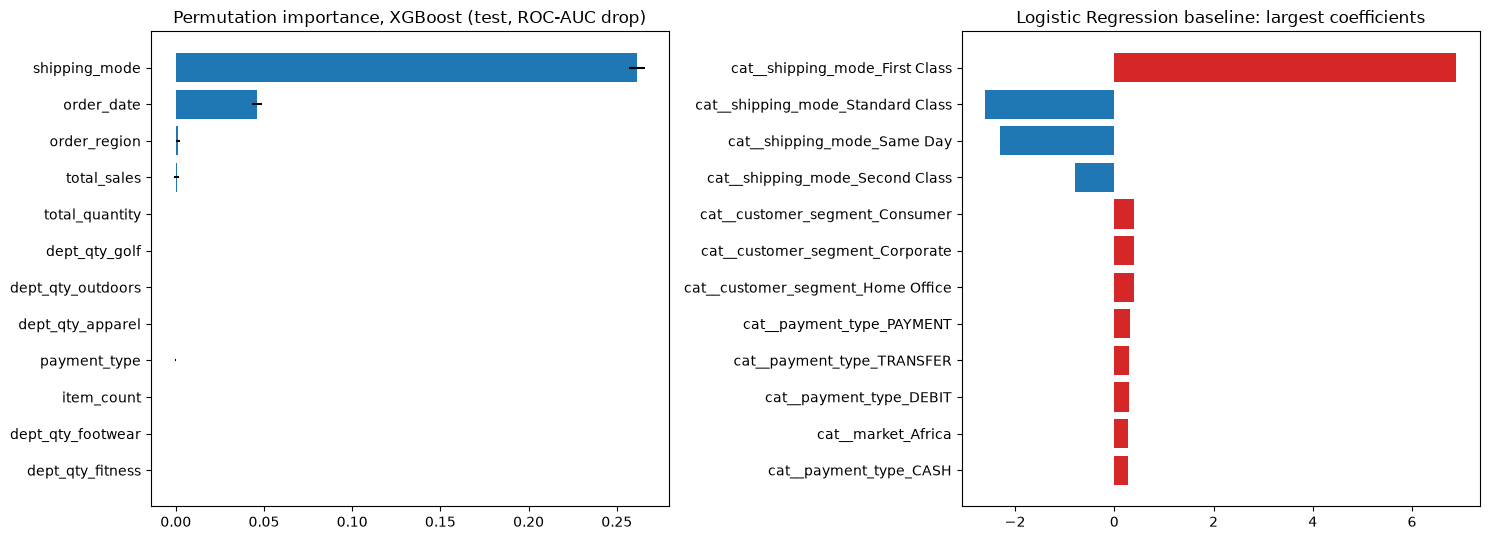

,feature,auc_drop_mean,auc_drop_std
0,shipping_mode,0.2616,0.0046
1,order_date,0.0458,0.0029
2,order_region,0.0013,0.0010
3,total_sales,0.0005,0.0013
4,total_quantity,0.0001,0.0002
5,dept_qty_golf,0.0000,0.0000
6,dept_qty_outdoors,0.0000,0.0001
7,dept_qty_apparel,0.0000,0.0000
8,payment_type,0.0000,0.0003
9,item_count,0.0000,0.0000


In [15]:
perm = permutation_importance(final_pipe, Xte, yte, scoring="roc_auc", n_repeats=5, random_state=t1.RANDOM_STATE)
importance = (pd.DataFrame({"feature": t1.INPUT_COLS, "auc_drop_mean": perm.importances_mean, "auc_drop_std": perm.importances_std})
              .sort_values("auc_drop_mean", ascending=False).reset_index(drop=True))
importance.to_csv(RES_DIR / "feature_importance_permutation.csv", index=False)

lr_names = lr_base.named_steps["prep"].get_feature_names_out()
lr_coef = (pd.DataFrame({"feature": lr_names, "coef": lr_base.named_steps["model"].coef_[0]})
           .assign(abs_coef=lambda d: d.coef.abs()).sort_values("abs_coef", ascending=False).reset_index(drop=True))
lr_coef.to_csv(RES_DIR / "lr_baseline_coefficients.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
top = importance.head(12)[::-1]
axes[0].barh(top.feature, top.auc_drop_mean, xerr=top.auc_drop_std); axes[0].set(title=f"Permutation importance, {FINAL_ALGO} (test, ROC-AUC drop)")
topc = lr_coef.head(12)[::-1]
axes[1].barh(topc.feature, topc.coef, color=np.where(topc.coef > 0, "tab:red", "tab:blue")); axes[1].set(title="Logistic Regression baseline: largest coefficients")
plt.tight_layout(); fig.savefig(FIG_DIR / "feature_importance.png", dpi=150); plt.show()
importance.head(10)

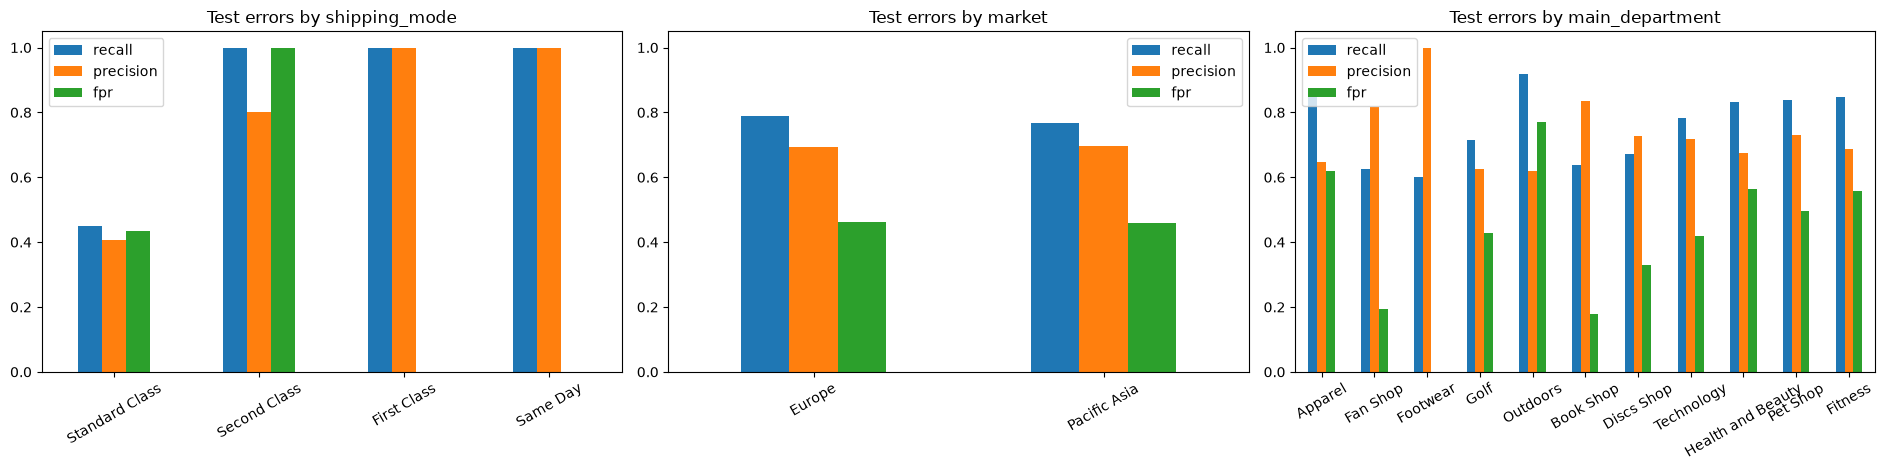

,split,dimension,segment,orders,late_rate,alert_rate,recall,precision,fpr,roc_auc,fp,fn
0,Validation,shipping_mode,Standard Class,5994,0.3937,0.3859,0.4000,0.4081,0.3767,0.5111,1369,1416
1,Validation,shipping_mode,Second Class,1943,0.7957,1.0000,1.0000,0.7957,1.0000,0.4870,397,0
2,Validation,shipping_mode,First Class,1497,1.0000,1.0000,1.0000,1.0000,NaN,NaN,0,0
3,Validation,shipping_mode,Same Day,537,0.5177,0.5177,1.0000,1.0000,0.0000,1.0000,0,0
4,Test,shipping_mode,Standard Class,4786,0.3974,0.4413,0.4501,0.4053,0.4355,0.5009,1256,1046
5,Test,shipping_mode,Second Class,1582,0.8028,1.0000,1.0000,0.8028,1.0000,0.5026,312,0
6,Test,shipping_mode,First Class,1233,1.0000,1.0000,1.0000,1.0000,NaN,NaN,0,0
7,Test,shipping_mode,Same Day,442,0.5226,0.5226,1.0000,1.0000,0.0000,1.0000,0,0
8,Validation,market,LATAM,4244,0.5631,0.5829,0.7322,0.7074,0.3905,0.7725,724,640
9,Validation,market,Europe,5727,0.5746,0.6211,0.7642,0.7071,0.4278,0.7794,1042,776


In [16]:
scored = pd.concat([valid.assign(split="Validation", score=final_pipe.predict_proba(Xva)[:, 1]),
                    test.assign(split="Test", score=s_final)])


def segment_table(col):
    rows = []
    for (split, seg), g in scored.groupby(["split", col], sort=False):
        m = t1.evaluate(g[t1.TARGET], g.score, FINAL_THR)
        rows.append({"split": split, "dimension": col, "segment": seg, "orders": m["n"], "late_rate": g[t1.TARGET].mean(),
                     **{k: m[k] for k in ["alert_rate", "recall", "precision", "fpr", "roc_auc", "fp", "fn"]}})
    return pd.DataFrame(rows)


segments = pd.concat([segment_table(c) for c in ["shipping_mode", "market", "main_department"]], ignore_index=True)
segments.to_csv(RES_DIR / "segment_errors.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, dim in zip(axes, ["shipping_mode", "market", "main_department"]):
    seg = segments[(segments.dimension == dim) & (segments.split == "Test")].set_index("segment")[["recall", "precision", "fpr"]]
    seg.plot.bar(ax=ax, rot=30); ax.set(title=f"Test errors by {dim}", xlabel="", ylim=(0, 1.05))
plt.tight_layout(); fig.savefig(FIG_DIR / "segment_errors.png", dpi=150); plt.show()
segments

In [17]:
from sklearn.tree import export_text
dt_pipe = fitted[("DecisionTree", "Full")]["pipe"]
dt_rules = export_text(dt_pipe.named_steps["model"], feature_names=list(dt_pipe.named_steps["prep"].get_feature_names_out()),
                       max_depth=3, decimals=2, show_weights=False)
(RES_DIR / "decision_tree_rules.txt").write_text(dt_rules)
print("Note: numeric splits are on standardised values (z-scores).")
print(dt_rules)

Note: numeric splits are on standardised values (z-scores).
|--- cat__shipping_mode_Standard Class <= 0.50
|   |--- cat__shipping_mode_Same Day <= 0.50
|   |   |--- cat__shipping_mode_Second Class <= 0.50
|   |   |   |--- class: 1
|   |   |--- cat__shipping_mode_Second Class >  0.50
|   |   |   |--- num__discount_rate <= 0.43
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__discount_rate >  0.43
|   |   |   |   |--- truncated branch of depth 2
|   |--- cat__shipping_mode_Same Day >  0.50
|   |   |--- num__order_hour <= -0.00
|   |   |   |--- class: 0
|   |   |--- num__order_hour >  -0.00
|   |   |   |--- class: 1
|--- cat__shipping_mode_Standard Class >  0.50
|   |--- num__total_sales <= 0.79
|   |   |--- num__total_discount <= 0.67
|   |   |   |--- num__total_discount <= 0.53
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- num__total_discount >  0.53
|   |   |   |   |--- class: 0
|   |   |--- num__total_discount >  0.67
|   |   |   |--- num__tot

### Canceled orders (excluded from training)

In [18]:
both = pd.concat([orders.assign(group="Delivered (modelled)"), canceled.assign(group="Shipping canceled")], ignore_index=True)
profile = pd.concat({col: pd.crosstab(both[col], both["group"], normalize="columns")
                     for col in ["shipping_mode", "market", "payment_type", "customer_segment", "order_status"]},
                    names=["dimension", "value"])
profile.to_csv(RES_DIR / "canceled_profile.csv")

cancel_rate_by_payment = pd.concat([orders, canceled]).groupby("payment_type")["delivery_status"].apply(lambda s: (s == t1.CANCELED).mean())
canceled_scored = canceled.assign(score=final_pipe.predict_proba(canceled[t1.INPUT_COLS])[:, 1])
canceled_scored["flag"] = canceled_scored.score >= FINAL_THR
canceled_summary = canceled_scored.groupby("order_status").agg(orders=("score", "size"), mean_risk=("score", "mean"), flagged_share=("flag", "mean"))
canceled_summary.loc["All"] = [len(canceled_scored), canceled_scored.score.mean(), canceled_scored.flag.mean()]
canceled_summary.to_csv(RES_DIR / "canceled_scored_summary.csv")
print(f"Canceled orders: {len(canceled):,}; order status:", canceled.order_status.value_counts().to_dict())
print("Cancellation rate by payment type:", cancel_rate_by_payment.round(4).to_dict())
display(canceled_summary)
profile

Canceled orders: 2,855; order status: {'SUSPECTED_FRAUD': 1488, 'CANCELED': 1367}
Cancellation rate by payment type: {'CASH': 0.0, 'DEBIT': 0.0, 'PAYMENT': 0.0, 'TRANSFER': 0.1579}


,orders,mean_risk,flagged_share
order_status,,,
CANCELED,1367.0000,0.5789,0.6189
SUSPECTED_FRAUD,1488.0000,0.5770,0.6136
All,2855.0000,0.5779,0.6161


group                             Delivered (modelled)  Shipping canceled
dimension        value                                                   
shipping_mode    First Class                    0.1527             0.1671
                 Same Day                       0.0542             0.0574
                 Second Class                   0.1949             0.1828
                 Standard Class                 0.5983             0.5926
market           Africa                         0.0587             0.0578
                 Europe                         0.2824             0.2795
                 LATAM                          0.2610             0.2687
                 Pacific Asia                   0.2679             0.2536
                 USCA                           0.1300             0.1405
payment_type     CASH                           0.1153             0.0000
                 DEBIT                          0.4029             0.0000
                 PAYMENT                        0.2399             0.0000
                 TRANSFER                       0.2420             1.0000
customer_segment Consumer                       0.5185             0.5271
                 Corporate                      0.3024             0.2939
                 Home Office                    0.1791             0.1790
order_status     CANCELED                       0.0000             0.4788
                 CLOSED                         0.1153             0.0000
                 COMPLETE                       0.3453             0.0000
                 ON_HOLD                        0.0576             0.0000
                 PAYMENT_REVIEW                 0.0112             0.0000
                 PENDING                        0.1164             0.0000
                 PENDING_PAYMENT                0.2287             0.0000
                 PROCESSING                     0.1256             0.0000
                 SUSPECTED_FRAUD                0.0000             0.5212

### Profit fields check (analysis only, not used in the final model)
`Benefit per order`, `Order Profit Per Order` and `Order Item Profit Ratio` are excluded from the model because their
availability at order placement is undefined. This check verifies that the exclusion does not throw away predictive signal:
1. relationships between the three fields;
2. univariate ROC-AUC of order-level profit features on each split;
3. the four models with and without profit features, (a) using the shipped validation-chosen parameters and (b) after
   re-tuning Random Forest and XGBoost on validation with the profit features. Test differences come with a paired bootstrap
   95% CI (1,000 resamples). Decisions are based on validation only.

In [19]:
pf_items = pd.read_csv(t1.ITEMS_PATH)
print("Benefit per order == Order Profit Per Order (rows):", (pf_items["Benefit per order"] == pf_items["Order Profit Per Order"]).mean())
print("Benefit per order == Order Item Profit Ratio x Order Item Total (within 2-decimal rounding of the ratio):",
      ((pf_items["Benefit per order"] - pf_items["Order Item Profit Ratio"] * pf_items["Order Item Total"]).abs()
       <= 0.0056 * pf_items["Order Item Total"]).mean())

pf_g = pf_items.groupby("Order Id")
pf_feats = pd.DataFrame({
    "order_benefit": pf_g["Benefit per order"].sum(),
    "order_profit_ratio": pf_g["Benefit per order"].sum() / pf_g["Order Item Total"].sum(),
    "item_ratio_mean": pf_g["Order Item Profit Ratio"].mean(),
    "item_ratio_min": pf_g["Order Item Profit Ratio"].min(),
    "loss_item_share": pf_g["Order Item Profit Ratio"].apply(lambda s: (s < 0).mean()),
}).reset_index()
assert np.allclose(pf_feats["order_benefit"], pf_g["Order Profit Per Order"].sum().to_numpy())
PROFIT_COLS = [c for c in pf_feats.columns if c != "Order Id"]

pf_train, pf_valid, pf_test = t1.chronological_split(orders.merge(pf_feats, on="Order Id", how="left"))
assert (pf_train["Order Id"].to_numpy() == train["Order Id"].to_numpy()).all() and len(pf_test) == len(test)
pf_splits = {"Train": pf_train, "Validation": pf_valid, "Test": pf_test}

profit_univariate = pd.DataFrame({f: {k: roc_auc_score(d[t1.TARGET], d[f]) for k, d in pf_splits.items()} for f in PROFIT_COLS}).T
profit_univariate.to_csv(RES_DIR / "profit_univariate_auc.csv")
print("\nUnivariate ROC-AUC (0.5 = no signal):")
profit_univariate

Benefit per order == Order Profit Per Order (rows): 1.0
Benefit per order == Order Item Profit Ratio x Order Item Total (within 2-decimal rounding of the ratio): 1.0



Univariate ROC-AUC (0.5 = no signal):


,Train,Validation,Test
order_benefit,0.4967,0.4969,0.5089
order_profit_ratio,0.4969,0.4986,0.5081
item_ratio_mean,0.4972,0.4988,0.5079
item_ratio_min,0.4975,0.4997,0.5083
loss_item_share,0.5027,0.5021,0.4979


In [20]:
from sklearn.model_selection import ParameterGrid

PF_FS = "Full+Profit"
t1.FEATURE_SETS[PF_FS] = {"cat": t1.CAT_FULL, "num": t1.NUM_COLS + PROFIT_COLS}
pf_cols = t1.INPUT_COLS + PROFIT_COLS
pf_y = {k: d[t1.TARGET] for k, d in pf_splits.items()}
pf_rng = np.random.default_rng(t1.RANDOM_STATE)
pf_boot = [pf_rng.integers(0, len(pf_test), len(pf_test)) for _ in range(1000)]
yt_np = pf_y["Test"].to_numpy()


def fit_score(algo, params, fs):
    p = t1.make_pipeline(t1.MODEL_FACTORIES[algo](**params), fs).fit(pf_train[pf_cols], pf_y["Train"])
    return p.predict_proba(pf_valid[pf_cols])[:, 1], p.predict_proba(pf_test[pf_cols])[:, 1]


def compare(algo, params, setting):
    (v0, t0), (v1, tw) = fit_score(algo, params, "Full"), fit_score(algo, params, PF_FS)
    diff = np.array([roc_auc_score(yt_np[i], tw[i]) - roc_auc_score(yt_np[i], t0[i]) for i in pf_boot])
    return {"setting": setting, "model": algo, "params": params,
            "valid_auc_without": roc_auc_score(pf_y["Validation"], v0), "valid_auc_with": roc_auc_score(pf_y["Validation"], v1),
            "test_auc_without": roc_auc_score(yt_np, t0), "test_auc_with": roc_auc_score(yt_np, tw),
            "test_diff_ci_low": np.quantile(diff, 0.025), "test_diff_ci_high": np.quantile(diff, 0.975)}


pf_rows = [compare(a, best_params(a, "Full"), "(a) shipped params")
           for a in ["LogisticRegression", "DecisionTree", "RandomForest", "XGBoost"]]

# (b) re-tune on validation with profit features, then compare the same parameters with / without profit
pf_retune = []
for algo in ["RandomForest", "XGBoost"]:
    for params in ParameterGrid(GRIDS[algo]):
        v1, _ = fit_score(algo, params, PF_FS)
        pf_retune.append({"model": algo, "params": params, "valid_auc_with_profit": roc_auc_score(pf_y["Validation"], v1)})
pf_retune = pd.DataFrame(pf_retune).sort_values("valid_auc_with_profit", ascending=False)
for algo in ["RandomForest", "XGBoost"]:
    best = pf_retune[pf_retune.model == algo].iloc[0]
    row = compare(algo, best["params"], "(b) re-tuned with profit")
    row["best_valid_auc_without_profit (shipped tuning)"] = tuning[(algo, "Full")]["valid_auc"].max()
    pf_rows.append(row)
t1.FEATURE_SETS.pop(PF_FS)

profit_check = pd.DataFrame(pf_rows)
profit_check.to_csv(RES_DIR / "profit_feature_check.csv", index=False)
best_with = profit_check.loc[profit_check.setting.str.startswith("(b)"), "valid_auc_with"].max()
best_without = comparison[(comparison.feature_set == "Full") & (comparison.model != "ModeOnlyBenchmark")].roc_auc.max()
print(f"Best validation ROC-AUC  without profit: {best_without:.4f}  |  with profit (re-tuned): {best_with:.4f}")
print("Decision (validation only):", "add profit features" if best_with > best_without + 0.005 else "no validation gain -> keep profit fields out of the model")
profit_check

Best validation ROC-AUC  without profit: 0.7767  |  with profit (re-tuned): 0.7766
Decision (validation only): no validation gain -> keep profit fields out of the model


,setting,model,params,valid_auc_without,valid_auc_with,test_auc_without,test_auc_with,test_diff_ci_low,test_diff_ci_high,best_valid_auc_without_profit (shipped tuning)
0,(a) shipped params,LogisticRegression,{'C': 10},0.7487,0.7489,0.7526,0.7527,-0.0011,0.0014,NaN
1,(a) shipped params,DecisionTree,"{'max_depth': 5, 'min_samples_leaf': 500}",0.7767,0.7729,0.7760,0.7742,-0.0068,0.0036,NaN
2,(a) shipped params,RandomForest,"{'max_depth': 16, 'max_features': 0.5, 'min_sa...",0.7755,0.7734,0.7767,0.7797,-0.0009,0.0068,NaN
3,(a) shipped params,XGBoost,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.7766,0.7696,0.7766,0.7726,-0.0070,-0.0013,NaN
4,(b) re-tuned with profit,RandomForest,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.7727,0.7741,0.7782,0.7808,-0.0017,0.0069,0.7755
5,(b) re-tuned with profit,XGBoost,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.7732,0.7766,0.7792,0.7838,-0.0002,0.0088,0.7766


## 8. Export final model (C6)

In [21]:
final_meta = save_model(final_pipe, "t1_final", FINAL_ALGO, "Full", fitted[(FINAL_ALGO, "Full")]["params"], FINAL_THR, t1.TRAIN_END,
                        {"validation": comparison[(comparison.model == FINAL_ALGO) & (comparison.feature_set == "Full")].iloc[0]
                                       .drop(["model", "complexity", "feature_set", "params"]).to_dict(),
                         "test": final_test.to_dict(), "test_mode_only_benchmark": test_eval.iloc[2].to_dict(),
                         "test_nomode": test_eval.iloc[1].to_dict(), "test_lookup_ceiling_auc": ceiling_auc})

reloaded = joblib.load(MODEL_DIR / "t1_final.joblib")
assert np.allclose(reloaded.predict_proba(Xte)[:, 1], s_final)

import inference
served = inference.model_fn(str(MODEL_DIR))
response = inference.output_fn(inference.predict_fn(inference.input_fn((MODEL_DIR / "example_request.json").read_text(), "application/json"), served), "application/json")
(MODEL_DIR / "example_response.json").write_text(json.dumps(json.loads(response), indent=2))
print(json.dumps({k: final_meta[k] for k in ["model_version", "algorithm", "params", "threshold", "fit_end"]}, indent=2))
print(json.dumps(json.loads(response), indent=2))

{
  "model_version": "T1-XGBoost-Full-20261016",
  "algorithm": "XGBoost",
  "params": {
    "colsample_bytree": 0.8,
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 20,
    "n_estimators": 200,
    "subsample": 0.8
  },
  "threshold": 0.4059200882911682,
  "fit_end": "2017-04-01"
}
{
  "predictions": [
    {
      "order_id": 68780,
      "risk_score": 0.384059,
      "pred_label": 0,
      "model_version": "T1-XGBoost-Full-20261016"
    },
    {
      "order_id": 68781,
      "risk_score": 0.395993,
      "pred_label": 0,
      "model_version": "T1-XGBoost-Full-20261016"
    },
    {
      "order_id": 68783,
      "risk_score": 0.40083,
      "pred_label": 0,
      "model_version": "T1-XGBoost-Full-20261016"
    }
  ]
}


## 9. Summary

In [22]:
summary = pd.DataFrame({
    "item": ["Final model", "Validation ROC-AUC", "Test ROC-AUC", "Test late recall", "Test precision", "Test F1",
             "Test alert rate", "Mode-only benchmark test ROC-AUC", "NoMode model test ROC-AUC", "Lookup ceiling test ROC-AUC",
             "XGBoost (Full) validation / test ROC-AUC",
             "Target ROC-AUC >= 0.80", "Target recall >= 0.75"],
    "value": [f"{FINAL_ALGO} {fitted[(FINAL_ALGO, 'Full')]['params']}", f"{final_meta['metrics']['validation']['roc_auc']:.4f}",
              f"{final_test.roc_auc:.4f}", f"{final_test.recall:.4f}", f"{final_test.precision:.4f}", f"{final_test.f1:.4f}",
              f"{final_test.alert_rate:.4f}", f"{test_eval.iloc[2].roc_auc:.4f}", f"{test_eval.iloc[1].roc_auc:.4f}", f"{ceiling_auc:.4f}",
              "{:.4f} / {:.4f}".format(*complexity_cmp.query("model == 'XGBoost' and feature_set == 'Full'")[["valid_auc", "test_auc"]].iloc[0]),
              "met" if final_test.roc_auc >= 0.80 else "not met", "met" if final_test.recall >= 0.75 else "not met"]})
summary.to_csv(RES_DIR / "summary.csv", index=False)
summary

,item,value
0,Final model,"XGBoost {'colsample_bytree': 0.8, 'learning_ra..."
1,Validation ROC-AUC,0.7766
2,Test ROC-AUC,0.7766
3,Test late recall,0.7744
4,Test precision,0.6960
5,Test F1,0.7331
6,Test alert rate,0.6413
7,Mode-only benchmark test ROC-AUC,0.7447
8,NoMode model test ROC-AUC,0.5317
9,Lookup ceiling test ROC-AUC,0.7762
